In [1]:
import utils
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, TwoSlopeNorm
from pathlib import Path
from itertools import product
from mne import (
    set_log_level,
    read_epochs,
    concatenate_epochs,
    pick_channels
)

from mne.decoding import (
    SlidingEstimator, GeneralizingEstimator,
    cross_val_multiscore
)

from sklearn.decomposition import PCA
from sklearn.preprocessing import robust_scale, RobustScaler, minmax_scale, normalize

from pymer4.models import lmer, lm, glm, glmer

from scipy.signal import savgol_filter

from tqdm.notebook import trange, tqdm

from mne.viz import plot_topomap

set_log_level("ERROR")

In [2]:
# access to the paths and settings
settings = utils.load_json("settings.json")
trigger_mapping = utils.load_json("trigger_mapping.json")
trigger_mapping = {int(i): trigger_mapping[i] for i in trigger_mapping.keys()}
dataset_path = Path(settings["dataset_path"])
raw_path = dataset_path.joinpath("MEG", "raw")
proc_path = dataset_path.joinpath("MEG", "processed")
beh_path = dataset_path.joinpath("BEH")

In [3]:
# load basic data
subject = "sub-700"
beh_files = utils.get_files(beh_path, "*.csv", strings=["main_", subject])
beh_files = [i for i in beh_files if "ses_0" not in i._str]
fif_files = utils.get_files(proc_path, "*.fif", strings=["dots-onset", "realtime", "epo.fif", subject])
fif_files = [i for i in fif_files if "ses_0" not in i._str]
meg_calib_file = utils.get_files(proc_path, "*.json", strings=["meg-calibration", subject])[0]
meg_calib = utils.load_json(meg_calib_file)

behaviour = pd.concat([pd.read_csv(i) for i in beh_files]).reset_index(drop=True)
behaviour = behaviour[[i for i in behaviour.columns.tolist() if "exp_timing" not in i]]
epochs = concatenate_epochs([read_epochs(i, verbose=False) for i in fif_files], add_offset=True, on_mismatch="ignore", verbose=False)
overlap = np.mean(epochs.events[:,2] == behaviour.trial_trigger.to_numpy()) * 100
print(f"epoch order overlaps in {overlap}%")

/tmp/ipykernel_225745/1940570370.py:12: RuntimeWarning: Concatenation of Annotations within Epochs is not supported yet. All annotations will be dropped.
  epochs = concatenate_epochs([read_epochs(i, verbose=False) for i in fif_files], add_offset=True, on_mismatch="ignore", verbose=False)


epoch order overlaps in 100.0%


In [4]:
conditions = behaviour.groupby(["counterfactual_label", "coherence_level"]).rt.count().reset_index()
conditions = conditions[["counterfactual_label", "coherence_level"]]
behaviour = behaviour.assign(confidence_rank=0.0)
for ix, (cf, ch) in conditions.iterrows():
    selection_map = (
        (behaviour.counterfactual_label == cf) &
        (behaviour.coherence_level == ch)
    )
    ranked_confidence = behaviour[selection_map].scale_response.rank(pct=True, na_option="bottom").to_numpy()
    behaviour.loc[selection_map, "confidence_rank"] = ranked_confidence

In [5]:
# epochs = epochs.filter(2,80)
epochs = epochs.decimate(2)
epochs = epochs.crop(-1.0, 1.1)
# epochs = epochs.crop(-0.25, 0.3)
times = epochs.times
info = epochs.info
epochs = epochs.to_data_frame()

In [6]:
misc = ["time", "condition", "epoch", "UADC009", "UADC010"]
sensors = [i for i in epochs.columns if not utils.many_is_in(["time", "condition", "epoch", "UADC009", "UADC010"], i)]

epochs_misc = epochs[misc]
epochs_sensors = epochs[sensors]

In [7]:
n_components = 10
pca = PCA(n_components=n_components)
scaler = RobustScaler()
scaler.fit(epochs_sensors.to_numpy())
pca.fit(scaler.transform(epochs_sensors.to_numpy()))

PCA(n_components=10)

In [ ]:
time_results = []
for time in tqdm(times):
    time_map = epochs_misc.time == time
    brain_data = epochs_sensors.loc[time_map].reset_index(drop=True)
    pcs = pd.DataFrame(pca.transform(scaler.transform(brain_data.to_numpy())))
    pc_labels = [f"PC{i+1}" for i in range(n_components)]
    pcs.columns = pc_labels

    data = pd.concat([behaviour, pcs], axis=1)
    data = pl.from_dataframe(data)

    for pc in pc_labels:
        model = glm(
            formula=f"{pc} ~ scale_response + counterfactual_label + coherence_level + response_correct + response_key + (counterfactual_label:coherence_level)",
            data=data,
            family="gaussian"
        )
        model.fit()

        results = model.result_fit.to_pandas()
        results = results.loc[results.term != "(Intercept)"]
        results = results.assign(time=time)
        results = results.assign(pc=pc)
        time_results.append(results)

  0%|          | 0/616 [00:00<?, ?it/s]

In [9]:
time_results = pd.concat(time_results)

In [30]:
event_timing = {
    0.0: "dots\non",
    0.35: "dots\noff",
    0.6: "scale\non"
}

terms_nice = {
    "coherence_level": "Coherence",
    "counterfactual_labellow": "Counterfactual\nEvidence",
    "counterfactual_label": "Counterfactual\nEvidence",
    "response_correctTRUE": "Accuracy",
    "response_correct": "Accuracy",
    "scale_response": "Confidence",
    "coherence_level:counterfactual_labellow": "Experimental\nCondition\nInteraction",
    "counterfactual_labellow:coherence_level": "Experimental\nCondition\nInteraction",
    "response_keyright": "Response Side",
    "response_key": "Response Side",
    "(counterfactual_label:coherence_level)": "Experimental Condition Interaction"
}

In [ ]:


f_title

'PC10 ~ Confidence + Counterfactual Evidence + Coherence + Accuracy + Response Side + (Counterfactual Evidence:Coherence)'

In [11]:
true_loadings = pd.DataFrame(
    pca.components_ * np.sqrt(pca.explained_variance_).reshape(-1,1),
    columns=info.ch_names[:-2],
    index=[f"PC{i+1}" for i in range(pca.n_components_)]
)

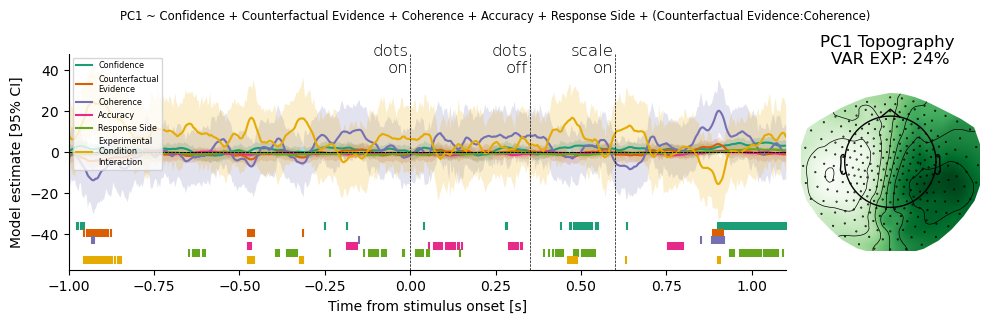

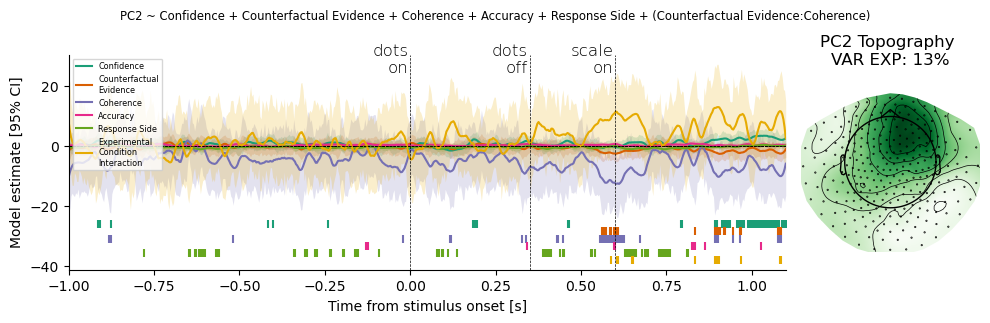

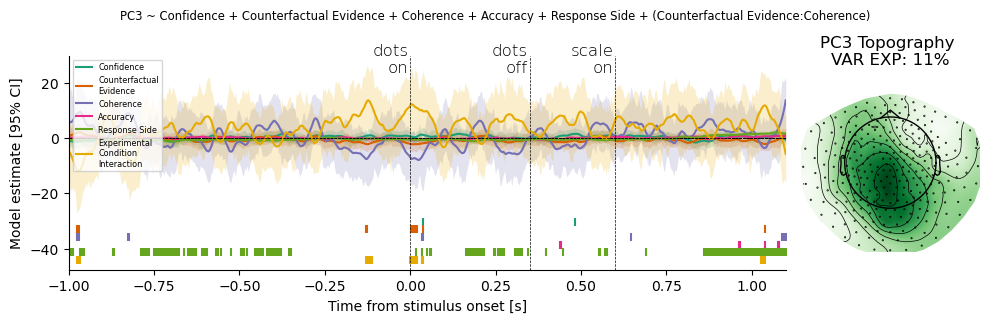

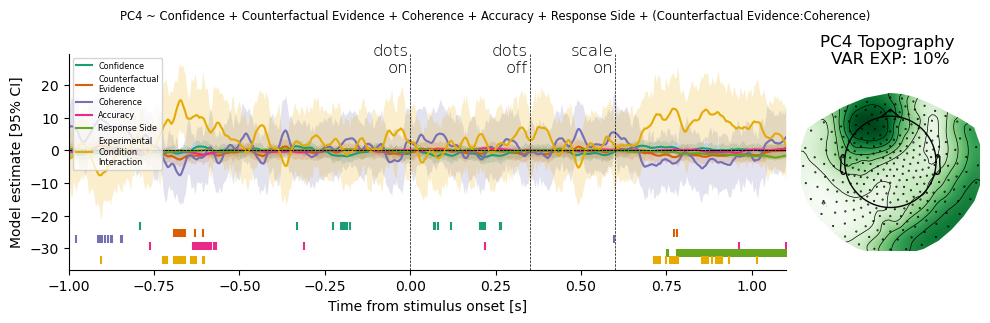

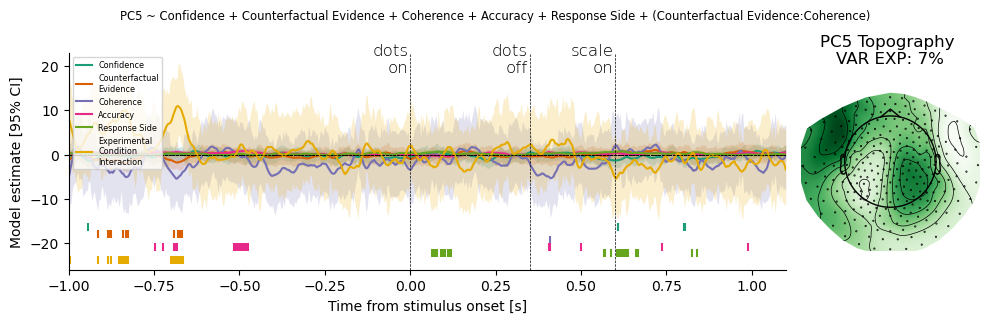

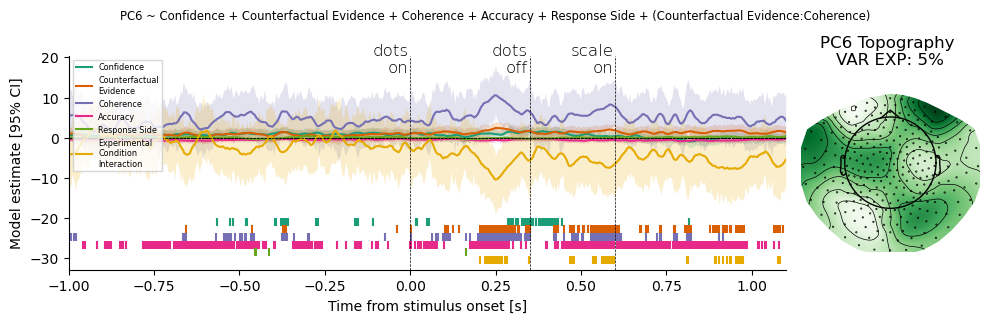

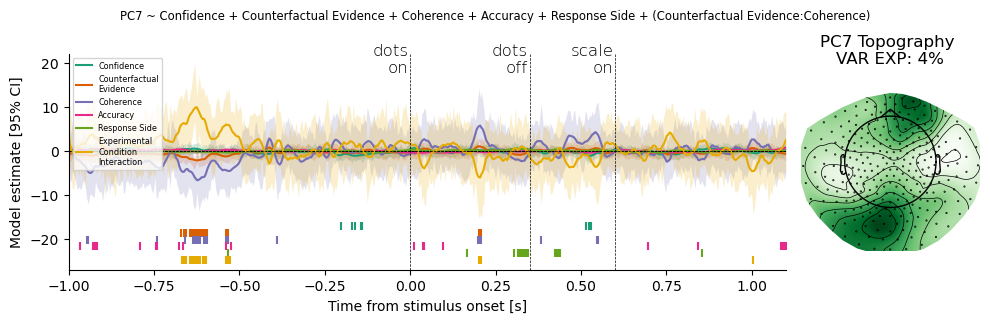

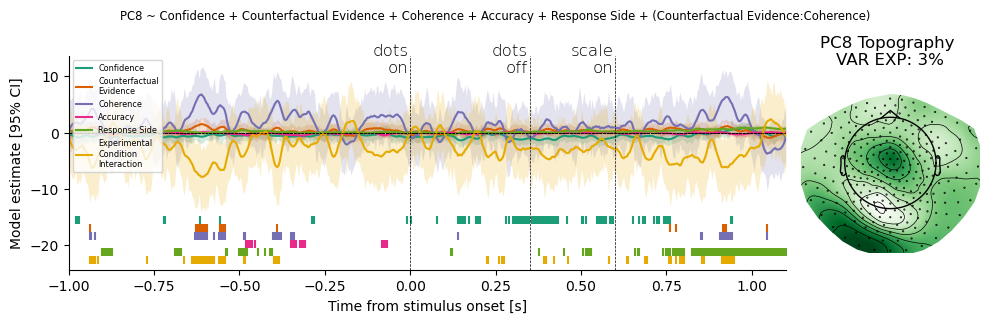

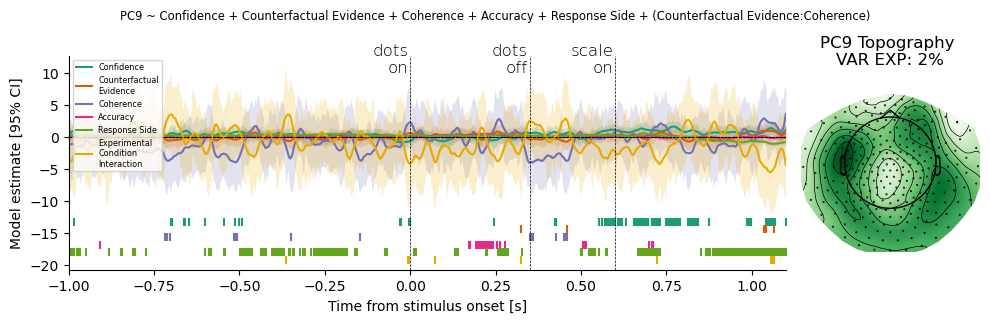

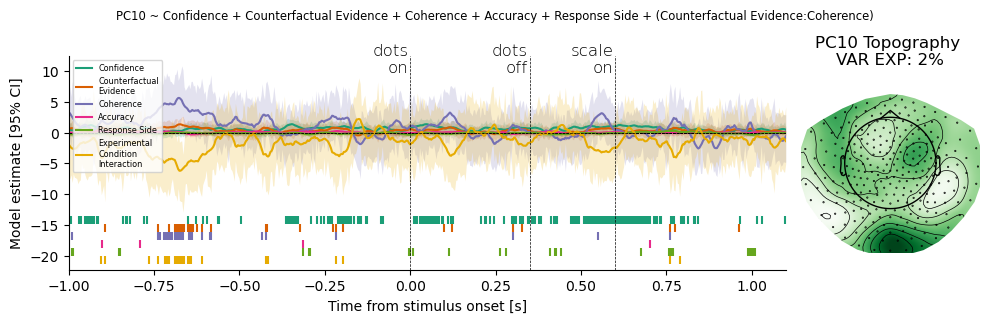

In [38]:
terms = time_results.term.unique().tolist()
colours = plt.cm.Dark2(np.linspace(0.1,0.9, num=8))

pc_labels = [f"PC{i+1}" for i in range(n_components)]
for pc_ix, pc in enumerate(pc_labels):
    big_min = time_results.loc[time_results.pc == pc].conf_low.min()
    big_max = time_results.loc[time_results.pc == pc].conf_high.max()
    max = big_max - big_max * 0.1
    f, ax = plt.subplots(1,2, figsize=(10, 3.25), width_ratios=(16, 4))
    for term_ix, term in enumerate(terms):
        sub_data = time_results.loc[
            (time_results.term == term) &
            (time_results.pc == pc)
        ]
        sig_map = (sub_data.p_value <= 0.05).to_numpy()
        
        min = big_min * (1.1 + 0.1*term_ix)

        ax[0].plot(times, savgol_filter(sub_data.estimate.to_numpy(), window_length=15, polyorder=3), color=colours[term_ix], label=terms_nice[term])
        ax[0].fill_between(times, sub_data.conf_low.to_numpy(), sub_data.conf_high.to_numpy(), alpha=0.2, lw=0, color=colours[term_ix])
        ax[0].axhline(0, lw=0.5, linestyle="dashed", c="black")
        ax[0].scatter(times[sig_map], np.tile(min, np.sum(sig_map)), marker="|", color=colours[term_ix])
    ax[0].legend(fontsize="xx-small", loc=2)
    ax[0].set_ylabel(r"Model estimate [95% CI]")
    ax[0].set_xlabel(r"Time from stimulus onset [s]")

    [ax[0].spines[loc].set_visible(False) for loc in ["top", "right"]];

    ax[0].set_xlim(times[0], times[-1])

    for i in event_timing.keys():
        ax[0].axvline(i, lw=0.5, c="black", linestyle="dashed")
        ax[0].text(i-0.005, max, event_timing[i], ha="right", weight="ultralight", size=12)

    loadings = minmax_scale(true_loadings.iloc[pc_ix].to_numpy())
    ax[1].set_title(f"{pc} Topography \nVAR EXP: {round(pca.explained_variance_ratio_[pc_ix]* 100)}%")
    ld = plot_topomap(
        loadings,
        info,
        cmap="Greens",
        axes=ax[1],
        show=False
    )

    f_title = f"{pc} ~ scale_response + counterfactual_label + coherence_level + response_correct + response_key + (counterfactual_label:coherence_level)"

    for k, v in terms_nice.items():
        f_title = f_title.replace(k, v)

    f_title = f_title.replace("\n", " ")

    f.suptitle(f_title, fontsize="small")
    plt.tight_layout()

    f.savefig(f"/home/maciek/git/DevComPsy_real_time_confidence/poster_inout/brain_{pc}_full_model.svg")